In [1]:
# Import required libraries

import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from pathlib import Path

dataset_path = Path("data/raw/fake_job_postings.csv")

if not dataset_path.exists():
    dataset_path = Path("../data/raw/fake_job_postings.csv")

df = pd.read_csv(dataset_path)
print("Dataset loaded successfully ")
print(f"Dataset shape: {df.shape}")

Dataset loaded successfully 
Dataset shape: (17880, 18)


In [3]:
df.head()

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [4]:
# Display all columns in the dataset

print(f"total columns:-  {len(df.columns)}\n")

for column in df.columns:
    print(column)

total columns:-  18

job_id
title
location
department
salary_range
company_profile
description
requirements
benefits
telecommuting
has_company_logo
has_questions
employment_type
required_experience
required_education
industry
function
fraudulent


In [5]:
# Check missing values 

missing_values = df.isnull().sum().sort_values(ascending=False)
missing_values

salary_range           15012
department             11547
required_education      8105
benefits                7212
required_experience     7050
function                6455
industry                4903
employment_type         3471
company_profile         3308
requirements            2696
location                 346
description                1
title                      0
job_id                     0
telecommuting              0
has_questions              0
has_company_logo           0
fraudulent                 0
dtype: int64

In [6]:
missing_percentage = (df.isnull().sum() / len(df))*100
print(missing_percentage.sort_values(ascending=False))

salary_range           83.959732
department             64.580537
required_education     45.329978
benefits               40.335570
required_experience    39.429530
function               36.101790
industry               27.421700
employment_type        19.412752
company_profile        18.501119
requirements           15.078300
location                1.935123
description             0.005593
title                   0.000000
job_id                  0.000000
telecommuting           0.000000
has_questions           0.000000
has_company_logo        0.000000
fraudulent              0.000000
dtype: float64


In [7]:
print("Job Distribution ")

print(df['fraudulent'].value_counts())

# Calculate percentage
print("\njob distribution percentage")
fraudulent_percentage = (df['fraudulent'].value_counts() / len(df)) * 100
print(fraudulent_percentage)

Job Distribution 
fraudulent
0    17014
1      866
Name: count, dtype: int64

job distribution percentage
fraudulent
0    95.1566
1     4.8434
Name: count, dtype: float64


Text(0, 0.5, 'Number of Jobs')

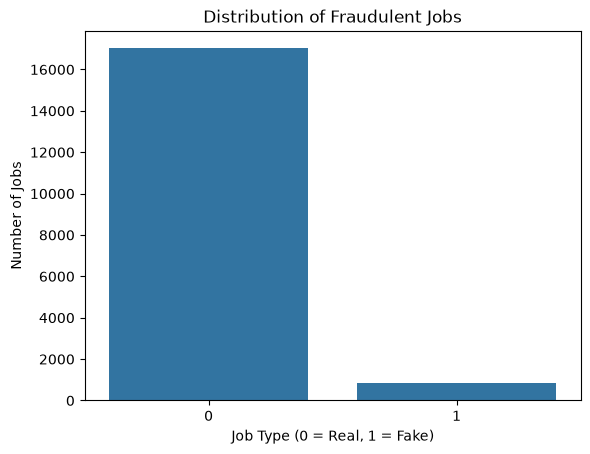

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns 

sns.countplot(x='fraudulent', data=df)

plt.title('Distribution of Fraudulent Jobs')
plt.xlabel("Job Type (0 = Real, 1 = Fake)")
plt.ylabel("Number of Jobs")

In [9]:
fake_jobs = df[df['fraudulent'] == 1]

fake_jobs[['title', 'company_profile', 'description', 'requirements']].head(3)

,title,company_profile,description,requirements
98,IC&E Technician,...,"IC&amp;E Technician | Bakersfield, CA Mt. Poso...","QualificationsKnowledge, Skills &amp; Abilitie..."
144,Forward Cap.,NaN,The group has raised a fund for the purchase o...,NaN
173,Technician Instrument & Controls,Edison International and Refined Resources hav...,Technician Instrument &amp; ControlsLocation D...,JOB QUALIFICATIONS-Ability to understand proce...


In [10]:
real_jobs = df[df['fraudulent'] == 0]

real_jobs[['title', 'company_profile', 'description', 'requirements']].head(3)

,title,company_profile,description,requirements
0,Marketing Intern,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...
1,Customer Service - Cloud Video Production,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...
2,Commissioning Machinery Assistant (CMA),Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...


In [11]:
#  Text column 

text_columns = ['title', 'company_profile', 'description', 'requirements', 'benefits']

print("Missing values in text columns")

# Check missing values in text columns
print(df[text_columns].isnull().sum())

# check data type of text columns
print("\nData types of text columns")
print(df[text_columns].dtypes)

Missing values in text columns
title                 0
company_profile    3308
description           1
requirements       2696
benefits           7212
dtype: int64

Data types of text columns
title              str
company_profile    str
description        str
requirements       str
benefits           str
dtype: object


In [12]:
# Create a copy of original dataset

df_clean = df.copy()

# Select text column 
text_columns = ['title', 'company_profile', 'description', 'requirements', 'benefits']

df_clean[text_columns] = df_clean[text_columns].fillna("")

# Check missing values after cleaning
print("Missing values after cleaning")
print(df_clean[text_columns].isnull().sum())

Missing values after cleaning
title              0
company_profile    0
description        0
requirements       0
benefits           0
dtype: int64


In [13]:
#  Select text columns

text_columns = ['title', 'company_profile', 'description', 'requirements', 'benefits']

# combine all text columns into a single column

df_clean["combined_text"] = df_clean[text_columns].agg(" ".join, axis=1)

# Display combined text
print("Combined text column:")
print(df_clean["combined_text"].iloc[0])

Combined text column:
Marketing Intern We're Food52, and we've created a groundbreaking and award-winning cooking site. We support, connect, and celebrate home cooks, and give them everything they need in one place.We have a top editorial, business, and engineering team. We're focused on using technology to find new and better ways to connect people around their specific food interests, and to offer them superb, highly curated information about food and cooking. We attract the most talented home cooks and contributors in the country; we also publish well-known professionals like Mario Batali, Gwyneth Paltrow, and Danny Meyer. And we have partnerships with Whole Foods Market and Random House.Food52 has been named the best food website by the James Beard Foundation and IACP, and has been featured in the New York Times, NPR, Pando Daily, TechCrunch, and on the Today Show.We're located in Chelsea, in New York City. Food52, a fast-growing, James Beard Award-winning online food community and

In [14]:
# Check combined text column

print("Total rows:", len(df_clean))

print("Combined text column created!")

print("\nFirst 3 job postings:\n")

for i in range(3):
    print(f"\nJob {i+1}:")
    print(df_clean["combined_text"].iloc[i][:500])

Total rows: 17880
Combined text column created!

First 3 job postings:


Job 1:
Marketing Intern We're Food52, and we've created a groundbreaking and award-winning cooking site. We support, connect, and celebrate home cooks, and give them everything they need in one place.We have a top editorial, business, and engineering team. We're focused on using technology to find new and better ways to connect people around their specific food interests, and to offer them superb, highly curated information about food and cooking. We attract the most talented home cooks and contributor

Job 2:
Customer Service - Cloud Video Production 90 Seconds, the worlds Cloud Video Production Service.90 Seconds is the worlds Cloud Video Production Service enabling brands and agencies to get high quality online video content shot and produced anywhere in the world. 90 Seconds makes video production fast, affordable, and all managed seamlessly in the cloud from purchase to publish. http://90#URL_fbe6559afac620a3

In [15]:
df_clean.head(3)

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent,combined_text
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,,0,1,0,Other,Internship,NaN,NaN,Marketing,0,"Marketing Intern We're Food52, and we've creat..."
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0,Customer Service - Cloud Video Production 90 S...
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,,0,1,0,NaN,NaN,NaN,NaN,NaN,0,Commissioning Machinery Assistant (CMA) Valor ...


In [16]:
import re
import html


def clean_text(text):

    # Convert HTML entities into normal text
    text = html.unescape(text)  

    text = re.sub(r"http\S+|www\S+|https\S+", " ", text)

    # Remove URL placeholders
    text = re.sub(r"#URL_[^#]*#", " ", text)

    text = text.lower()

    # Remove extra spaces and newlines
    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [17]:
df_clean["clean_text"] = df_clean["combined_text"].apply(clean_text)

print("Cleaned text column created!")

print("\nOriginal Text:\n")
print(df_clean["combined_text"].iloc[0][:300])

print("\nCleaned Text:\n")
print(df_clean["clean_text"].iloc[0][:300])

Cleaned text column created!

Original Text:

Marketing Intern We're Food52, and we've created a groundbreaking and award-winning cooking site. We support, connect, and celebrate home cooks, and give them everything they need in one place.We have a top editorial, business, and engineering team. We're focused on using technology to find new and 

Cleaned Text:

marketing intern we're food52, and we've created a groundbreaking and award-winning cooking site. we support, connect, and celebrate home cooks, and give them everything they need in one place.we have a top editorial, business, and engineering team. we're focused on using technology to find new and 


In [18]:
text = df_clean["clean_text"].iloc[0]

tokens  = text.split()

print("Original Text:\n")
print(text)

print("\nTokens:\n")
print(tokens)

Original Text:

marketing intern we're food52, and we've created a groundbreaking and award-winning cooking site. we support, connect, and celebrate home cooks, and give them everything they need in one place.we have a top editorial, business, and engineering team. we're focused on using technology to find new and better ways to connect people around their specific food interests, and to offer them superb, highly curated information about food and cooking. we attract the most talented home cooks and contributors in the country; we also publish well-known professionals like mario batali, gwyneth paltrow, and danny meyer. and we have partnerships with whole foods market and random house.food52 has been named the best food website by the james beard foundation and iacp, and has been featured in the new york times, npr, pando daily, techcrunch, and on the today show.we're located in chelsea, in new york city. food52, a fast-growing, james beard award-winning online food community and crowd

In [19]:
import nltk

nltk.download('stopwords')

from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

print(f"Total Stopwords: {len(stop_words)}")

print("some stopwords: ", list(stop_words)[:10])

Total Stopwords: 198
some stopwords:  ['for', "he'll", 'and', 'some', 'its', 'mustn', "shan't", "wouldn't", 'don', 'an']


[nltk_data] Downloading package stopwords to
[nltk_data]     /home/codespace/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [20]:
text = df_clean["clean_text"].iloc[0]

tokens = text.split()

filtered_tokens = [
    word for word in tokens
    if word not in stop_words
]

print("Before:", tokens[:30])
print("\nAfter:", filtered_tokens[:30])

Before: ['marketing', 'intern', "we're", 'food52,', 'and', "we've", 'created', 'a', 'groundbreaking', 'and', 'award-winning', 'cooking', 'site.', 'we', 'support,', 'connect,', 'and', 'celebrate', 'home', 'cooks,', 'and', 'give', 'them', 'everything', 'they', 'need', 'in', 'one', 'place.we', 'have']

After: ['marketing', 'intern', 'food52,', 'created', 'groundbreaking', 'award-winning', 'cooking', 'site.', 'support,', 'connect,', 'celebrate', 'home', 'cooks,', 'give', 'everything', 'need', 'one', 'place.we', 'top', 'editorial,', 'business,', 'engineering', 'team.', 'focused', 'using', 'technology', 'find', 'new', 'better', 'ways']


In [21]:
import nltk

nltk.download("wordnet")
nltk.download("omw-1.4")

from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

print("Lemmatizer Ready!")

[nltk_data] Downloading package wordnet to
[nltk_data]     /home/codespace/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /home/codespace/nltk_data...


Lemmatizer Ready!


[nltk_data]   Package omw-1.4 is already up-to-date!


In [22]:
words = ["running", "runs", "studies", "employees", "created"]

for word in words:
    print(word, "->", lemmatizer.lemmatize(word))

running -> running
runs -> run
studies -> study
employees -> employee
created -> created


In [23]:
import nltk

nltk.download("punkt_tab")
nltk.download("averaged_perceptron_tagger_eng")
nltk.download("wordnet")
nltk.download("omw-1.4")

print("NLTK resources downloaded!")

NLTK resources downloaded!


[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/codespace/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /home/codespace/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /home/codespace/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /home/codespace/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [24]:
from nltk import pos_tag
from nltk.tokenize import word_tokenize

sentence = "Employees are running and working efficiently."

tokens = word_tokenize(sentence)

pos_tags = pos_tag(tokens)

print("Tokens:")
print(tokens)

print("\nPOS Tags:")
print(pos_tags)

Tokens:
['Employees', 'are', 'running', 'and', 'working', 'efficiently', '.']

POS Tags:
[('Employees', 'NNS'), ('are', 'VBP'), ('running', 'VBG'), ('and', 'CC'), ('working', 'VBG'), ('efficiently', 'RB'), ('.', '.')]


In [25]:
# POS Tagging + Lemmatization
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet
from nltk import pos_tag

lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(tag):

    if tag.startswith("J"):
        return wordnet.ADJ

    elif tag.startswith("V"):
        return wordnet.VERB

    elif tag.startswith("N"):
        return wordnet.NOUN

    elif tag.startswith("R"):
        return wordnet.ADV

    else:
        return wordnet.NOUN


words = ["running", "runs", "studies", "employees", "created"]

tagged_words = pos_tag(words)

for word, tag in tagged_words:

    pos = get_wordnet_pos(tag)

    lemma = lemmatizer.lemmatize(word, pos)

    print(f"{word} -> {lemma}")

running -> run
runs -> run
studies -> study
employees -> employee
created -> create


In [26]:
import re
import nltk

from nltk import pos_tag
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer

In [27]:
nltk.download("punkt_tab")
nltk.download("averaged_perceptron_tagger_eng")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/codespace/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /home/codespace/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /home/codespace/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /home/codespace/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /home/codespace/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [28]:
lemmatizer = WordNetLemmatizer()

stop_words = set(stopwords.words("english"))

# Important: Keep negation words
stop_words = stop_words - {"no", "not", "nor"}

print("Lemmatizer initialized!")
print("Total Stopwords:", len(stop_words))

Lemmatizer initialized!
Total Stopwords: 195


In [29]:
def get_wordnet_pos(tag):

    if tag.startswith("J"):
        return wordnet.ADJ

    elif tag.startswith("V"):
        return wordnet.VERB

    elif tag.startswith("N"):
        return wordnet.NOUN

    elif tag.startswith("R"):
        return wordnet.ADV

    else:
        return wordnet.NOUN

In [30]:
def preprocess_text(text):

    # Step 1: Handle missing values
    if not isinstance(text, str):
        return ""

    # Step 2: Tokenization
    tokens = word_tokenize(text)

    # Step 3: Remove punctuation and stopwords
    tokens = [
        word for word in tokens
        if word.isalpha() and word not in stop_words
    ]

    # Step 4: POS Tagging
    tagged_words = pos_tag(tokens)

    # Step 5: Lemmatization
    processed_words = []

    for word, tag in tagged_words:

        pos = get_wordnet_pos(tag)

        lemma = lemmatizer.lemmatize(word, pos)

        processed_words.append(lemma)

    # Step 6: Join words
    return " ".join(processed_words)

In [31]:
sample_text = """
We are hiring developers who are working on new applications.
Employees created innovative projects.
"""

result = preprocess_text(sample_text)

print("Original Text:")
print(sample_text)

print("\nProcessed Text:")
print(result)

Original Text:

We are hiring developers who are working on new applications.
Employees created innovative projects.


Processed Text:
We hire developer work new application Employees create innovative project


In [32]:
df_clean["preprocessed_text"] = df_clean["clean_text"].head(5).apply(preprocess_text)
print(df_clean[["clean_text","preprocessed_text"]].head(5))

                                          clean_text  \
0  marketing intern we're food52, and we've creat...   
1  customer service - cloud video production 90 s...   
2  commissioning machinery assistant (cma) valor ...   
3  account executive - washington dc our passion ...   
4  bill review manager spotsource solutions llc i...   

                                   preprocessed_text  
0  marketing intern create groundbreaking cook si...  
1  customer service cloud video production second...  
2  commission machinery assistant cma valor servi...  
3  account executive washington dc passion improv...  
4  bill review manager spotsource solution llc gl...  


In [33]:
print("Total Dataset Rows:", len(df_clean))

print(
    "Processed Non-Empty Rows:",
    (df_clean["preprocessed_text"].str.len() > 0).sum()
)

print(
    df_clean[["preprocessed_text", "fraudulent"]].head()
)

Total Dataset Rows: 17880
Processed Non-Empty Rows: 5
                                   preprocessed_text  fraudulent
0  marketing intern create groundbreaking cook si...           0
1  customer service cloud video production second...           0
2  commission machinery assistant cma valor servi...           0
3  account executive washington dc passion improv...           0
4  bill review manager spotsource solution llc gl...           0


In [34]:
# Practical TF-IDF Example

from sklearn.feature_extraction.text import TfidfVectorizer

documents = [
    "python developer required",
    "java developer required",
    "python engineer needed"
]


tfidf = TfidfVectorizer()

tfidf_matrix = tfidf.fit_transform(documents)

print("Vocabulary:", tfidf.get_feature_names_out())

print("\nTF-IDF Matrix:\n")
print(tfidf_matrix.toarray())

Vocabulary: ['developer' 'engineer' 'java' 'needed' 'python' 'required']

TF-IDF Matrix:

[[0.57735027 0.         0.         0.         0.57735027 0.57735027]
 [0.51785612 0.         0.68091856 0.         0.         0.51785612]
 [0.         0.62276601 0.         0.62276601 0.4736296  0.        ]]


In [35]:
# Apply preprocessing to complete dataset

df_clean["preprocessed_text"] = (
    df_clean["clean_text"].apply(preprocess_text)
)

print("Preprocessing completed!")

print("Total Rows:", len(df_clean))

print(
    "Processed Rows:",
    (df_clean["preprocessed_text"].str.len() > 0).sum()
)

Preprocessing completed!
Total Rows: 17880
Processed Rows: 17880


In [36]:
from sklearn.model_selection import train_test_split

X = df_clean["preprocessed_text"]
y = df_clean["fraudulent"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Data:", X_train.shape)
print("Test Data:", X_test.shape)

Training Data: (14304,)
Test Data: (3576,)


In [37]:
# 3. TF-IDF Vectorization

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

Training TF-IDF Shape: (14304, 10000)
Testing TF-IDF Shape: (3576, 10000)


In [38]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

In [39]:
# Step 2: Models define karo
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Naive Bayes": MultinomialNB(),

    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42
    )
}

In [40]:
# Step 3: Pipeline create aur train karo
results = []

for model_name, classifier in models.items():

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=10000,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95
        )),

        ("classifier", classifier)
    ])

    # Train
    pipeline.fit(X_train, y_train)

    # Predict
    y_pred = pipeline.predict(X_test)

    # Evaluate
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0)
    })

    print(model_name, "Training Completed!")

Logistic Regression Training Completed!
Naive Bayes Training Completed!
Linear SVM Training Completed!


In [41]:
import pandas as pd

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

print(results_df)

                 Model  Accuracy  Precision    Recall  F1 Score
2           Linear SVM  0.984340   0.850299  0.820809  0.835294
0  Logistic Regression  0.970358   0.640167  0.884393  0.742718
1          Naive Bayes  0.961689   0.730769  0.329480  0.454183


In [42]:
categorical_features = [
    "employment_type",
    "required_experience",
    "required_education",
    "industry",
    "function",
    "location"
]

In [43]:
numerical_features = [
    "telecommuting",
    "has_company_logo",
    "has_questions"
]

In [44]:
# Check selected columns
selected_features = (
    ["preprocessed_text"]
    + categorical_features
    + numerical_features
)

print("Selected Features:")
print(selected_features)

print("\nMissing Values (%):")
print(
    (df_clean[selected_features].isnull().mean() * 100)
    .round(2)
)

print("\nDataset Shape:", df_clean[selected_features].shape)

Selected Features:
['preprocessed_text', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'location', 'telecommuting', 'has_company_logo', 'has_questions']

Missing Values (%):
preprocessed_text       0.00
employment_type        19.41
required_experience    39.43
required_education     45.33
industry               27.42
function               36.10
location                1.94
telecommuting           0.00
has_company_logo        0.00
has_questions           0.00
dtype: float64

Dataset Shape: (17880, 10)


In [45]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

In [46]:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [47]:
text_transformer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 1),
    min_df=3,
    max_df=0.95,
    dtype="float32"
)

In [48]:
numerical_transformer = "passthrough"

In [49]:
preprocessor = ColumnTransformer(
    transformers=[
        ("text", text_transformer, "preprocessed_text"),
        ("categorical", categorical_transformer, categorical_features),
        ("numerical", numerical_transformer, numerical_features)
    ]
)

In [50]:
# Select input features
X = df_clean[selected_features]

# Target variable
y = df_clean["fraudulent"]

# Fit and transform data
X_transformed = preprocessor.fit_transform(X)

print("Original Shape:", X.shape)
print("Transformed Shape:", X_transformed.shape)
print("Transformation Completed!")

/workspaces/fake-job-detection-nlp-ml/.venv/lib/python3.14/site-packages/sklearn/feature_extraction/text.py:2049: UserWarning: Only (<class 'numpy.float64'>, <class 'numpy.float32'>, <class 'numpy.float16'>) 'dtype' should be used. float32 'dtype' will be converted to np.float64.
  warnings.warn(


Original Shape: (17880, 10)
Transformed Shape: (17880, 8307)
Transformation Completed!


In [51]:
from sklearn.model_selection import train_test_split

X = df_clean[selected_features]
y = df_clean["fraudulent"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (14304, 10)
Testing Shape: (3576, 10)


In [52]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

In [53]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Naive Bayes": MultinomialNB(),

    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42
    )
}

In [55]:
import pandas as pd

cv = StratifiedKFold(
    n_splits=2,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

results = []

for model_name, classifier in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )

    results.append({
        "Model": model_name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean()
    })

    print(model_name, "Completed!")

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

print(results_df)

/workspaces/fake-job-detection-nlp-ml/.venv/lib/python3.14/site-packages/sklearn/feature_extraction/text.py:2049: UserWarning: Only (<class 'numpy.float64'>, <class 'numpy.float32'>, <class 'numpy.float16'>) 'dtype' should be used. float32 'dtype' will be converted to np.float64.
  warnings.warn(
/workspaces/fake-job-detection-nlp-ml/.venv/lib/python3.14/site-packages/sklearn/feature_extraction/text.py:2049: UserWarning: Only (<class 'numpy.float64'>, <class 'numpy.float32'>, <class 'numpy.float16'>) 'dtype' should be used. float32 'dtype' will be converted to np.float64.
  warnings.warn(


Logistic Regression Completed!


/workspaces/fake-job-detection-nlp-ml/.venv/lib/python3.14/site-packages/sklearn/feature_extraction/text.py:2049: UserWarning: Only (<class 'numpy.float64'>, <class 'numpy.float32'>, <class 'numpy.float16'>) 'dtype' should be used. float32 'dtype' will be converted to np.float64.
  warnings.warn(
/workspaces/fake-job-detection-nlp-ml/.venv/lib/python3.14/site-packages/sklearn/feature_extraction/text.py:2049: UserWarning: Only (<class 'numpy.float64'>, <class 'numpy.float32'>, <class 'numpy.float16'>) 'dtype' should be used. float32 'dtype' will be converted to np.float64.
  warnings.warn(


Naive Bayes Completed!


/workspaces/fake-job-detection-nlp-ml/.venv/lib/python3.14/site-packages/sklearn/feature_extraction/text.py:2049: UserWarning: Only (<class 'numpy.float64'>, <class 'numpy.float32'>, <class 'numpy.float16'>) 'dtype' should be used. float32 'dtype' will be converted to np.float64.
  warnings.warn(
/workspaces/fake-job-detection-nlp-ml/.venv/lib/python3.14/site-packages/sklearn/feature_extraction/text.py:2049: UserWarning: Only (<class 'numpy.float64'>, <class 'numpy.float32'>, <class 'numpy.float16'>) 'dtype' should be used. float32 'dtype' will be converted to np.float64.
  warnings.warn(


Linear SVM Completed!
                 Model  Accuracy  Precision    Recall  F1 Score
2           Linear SVM  0.979376   0.807881  0.757629  0.780454
0  Logistic Regression  0.962039   0.574970  0.829800  0.678651
1          Naive Bayes  0.958473   0.978261  0.145716  0.253334


In [56]:
text_transformer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 1),
    min_df=3,
    max_df=0.95
)

preprocessor = ColumnTransformer(
    transformers=[
        ("text", text_transformer, "preprocessed_text"),
        ("categorical", categorical_transformer, categorical_features),
        ("numerical", "passthrough", numerical_features)
    ]
)

In [57]:
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

final_model = Pipeline(steps=[
    ("preprocessor", preprocessor),

    ("classifier", LinearSVC(
        class_weight="balanced",
        random_state=42
    ))
])

In [58]:
final_model.fit(X_train, y_train)

print("Final Linear SVM Training Completed!")

Final Linear SVM Training Completed!


In [59]:
y_pred = final_model.predict(X_test)

print("Prediction Completed!")

Prediction Completed!


In [60]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Real Job", "Fake Job"]
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.985738255033557
Precision: 0.8426966292134831
Recall: 0.8670520231213873
F1 Score: 0.8547008547008547

Classification Report:
              precision    recall  f1-score   support

    Real Job       0.99      0.99      0.99      3403
    Fake Job       0.84      0.87      0.85       173

    accuracy                           0.99      3576
   macro avg       0.92      0.93      0.92      3576
weighted avg       0.99      0.99      0.99      3576


Confusion Matrix:
[[3375   28]
 [  23  150]]


In [61]:
import os
import joblib

# Create models directory if it doesn't exist
os.makedirs("models", exist_ok=True)

# Save complete pipeline
model_path = "models/fake_job_model.pkl"

joblib.dump(final_model, model_path)

print("Model saved successfully!")
print("Model Location:", model_path)

Model saved successfully!
Model Location: models/fake_job_model.pkl


In [62]:
import joblib

loaded_model = joblib.load("models/fake_job_model.pkl")

print("Model loaded successfully!")

Model loaded successfully!


In [63]:
# Test dataset se ek job select karo
sample_job = X_test.iloc[[0]]

# Actual result
actual = y_test.iloc[0]

# Model prediction
prediction = loaded_model.predict(sample_job)[0]

print("Actual Result:", actual)
print("Predicted Result:", prediction)

if prediction == 1:
    print("Prediction: Fake Job")
else:
    print("Prediction: Real Job")

Actual Result: 0
Predicted Result: 0
Prediction: Real Job


In [ ]:
sample_jobs = X_test.iloc[:5]

predictions = loaded_model.predict(sample_jobs)

for index, prediction in enumerate(predictions):
    result = "Fake Job" if prediction == 1 else "Real Job"
    print(f"Job {index + 1}: {result}")

Job 1: Real Job
Job 2: Real Job
Job 3: Real Job
Job 4: Real Job
Job 5: Real Job


: 